In [1]:
import sys

import numpy
import pandas
import sklearn

print(sys.version.split()[0], numpy.__version__, pandas.__version__, sklearn.__version__)

3.14.7 2.5.3 3.0.6 1.9.1


In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

SEED = 2666

data = pd.read_csv("data/heart_disease.csv")
feature_names = [c for c in data.columns if c != "disease"]
X, y = data[feature_names].to_numpy(), data["disease"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=SEED
)
print(data.shape, round(y.mean(), 3), X_train.shape, X_test.shape)

(297, 14) 0.461 (207, 13) (90, 13)


In [3]:
data.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,disease
0,63,1,1,145,233,1,2,150,0,2.3,3,0,6,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3,3,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2,7,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0,3,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0,3,0


task 1

In [4]:
toy = pd.DataFrame({
    "age_55_plus": [1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0],
    "exercise_angina": [1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0],
    "male": [1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0],
    "high_bp": [1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0],
    "disease": [1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0],
})

1

In [5]:
#[1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0]
#1 count: 6; 0 count:6
#total: 12
#p1=0.5 p2=0.5
#-0.5 * log2(0.5) - 0.5 * log2(0.5)= 1
#entropy = 1

2

age_55_plus gain:
0.350

exercise_angina gain: 
0.459 

male gain:
0.000

high_bp gain:
0.082

3

age_55_plus

Value 0: 6 patients, 1 diseased and 5 disease-free; entropy = 0.650.

Value 1: 2 patients, 1 diseased and 1 disease-free; entropy = 1.

male

Value 0: 5 patients, 2 diseased and 3 disease-free; entropy = 0.971.

Value 1: 3 patients, all disease-free; entropy = 0.

high_bp

Value 0: 5 patients, 1 diseased and 4 disease-free; entropy = 0.722.

Value 1: 3 patients, 1 diseased and 2 disease-free; entropy = 0.918.

age_55_plus gain:
0.074

male gain:
0.204

high_bp gain:
0.016

At the root, male has an information gain of zero because both groups contain the same number of diseased and disease-free patients. However, after splitting by exercise_angina, the groups are no longer balanced in the same way. Within the exercise_angina = 0 branch, male separates all three male patients into the disease-free group, so it becomes the best feature for the next split.

## Task 3

In [6]:
def entropy(y):
    """Entropy in bits of an array of integer class labels."""
    if len(y) == 0:
        return 0.0

    _, counts = np.unique(y, return_counts=True)
    p = counts / len(y)
    return -np.sum(p * np.log2(p))


def information_gain(y, left):
    """Parent entropy minus weighted child entropy."""
    left = np.asarray(left, dtype=bool)
    right = ~left

    if left.sum() == 0 or right.sum() == 0:
        return 0.0

    return entropy(y) - (
        left.sum() / len(y) * entropy(y[left])
        + right.sum() / len(y) * entropy(y[right])
    )


def best_split(X, y, min_samples_leaf=1):
    """Return the best feature index, midpoint threshold and gain."""
    best = None

    for j in range(X.shape[1]):
        values = np.unique(X[:, j])
        thresholds = (values[:-1] + values[1:]) / 2

        for threshold in thresholds:
            left = X[:, j] <= threshold
            right = ~left

            if (left.sum() < min_samples_leaf or
                    right.sum() < min_samples_leaf):
                continue

            gain = information_gain(y, left)
            if best is None or gain > best[2] + 1e-12:
                best = (j, float(threshold), float(gain))

    return best


def build_tree(X, y, max_depth=None, min_samples_leaf=1, depth=0):
    """Grow a decision tree recursively."""
    labels, counts = np.unique(y, return_counts=True)
    majority = labels[np.argmax(counts)]

    if len(labels) == 1 or (
        max_depth is not None and depth >= max_depth
    ):
        return {"leaf": int(majority)}

    split = best_split(X, y, min_samples_leaf)

    if split is None:
        return {"leaf": int(majority)}

    j, threshold, gain = split
    left_mask = X[:, j] <= threshold

    return {
        "feature": j,
        "threshold": threshold,
        "left": build_tree(
            X[left_mask], y[left_mask],
            max_depth, min_samples_leaf, depth + 1
        ),
        "right": build_tree(
            X[~left_mask], y[~left_mask],
            max_depth, min_samples_leaf, depth + 1
        )
    }


def predict_tree(tree, X):
    """Return one predicted label per row of X."""
    predictions = []

    for row in X:
        node = tree

        while "leaf" not in node:
            j = node["feature"]
            if row[j] <= node["threshold"]:
                node = node["left"]
            else:
                node = node["right"]

        predictions.append(node["leaf"])

    return np.asarray(predictions)

In [7]:
y = toy["disease"].to_numpy()
parent_entropy = entropy(y)

print(f"Parent entropy = {parent_entropy:} bits")

Parent entropy = 1.0 bits


In [8]:
features = ["age_55_plus", "exercise_angina", "male", "high_bp"]
for feature in features:
    gain = information_gain(
        toy["disease"], toy[feature].to_numpy() == 0
    )
    print(f"{feature}: {gain:.3f}")

age_55_plus: 0.350
exercise_angina: 0.459
male: 0.000
high_bp: 0.082


In [9]:
y = toy["disease"].to_numpy()
X = toy.drop(columns=["disease"]).to_numpy()
best_split(X, y)

(1, 0.5, 0.4591479170272448)

Feature 1 is excercise_angina. 

midpoint threshold: 0.5

gain: 0.4591479170272448

In [10]:
best_split(X_train, y_train)

(11, 0.5, 0.2058977602604175)

not the same

## Task 3

In [11]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
model = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=SEED)
scores = cross_validate(model, X_train, y_train, cv=cv, scoring="accuracy", return_train_score=True)
print(scores["train_score"].mean(), scores["test_score"].mean(), scores["test_score"].std())

0.8538809784592918 0.7493612078977933 0.08629477133039802


a.

In [12]:
depths = [1, 2, 3, 4, 5, 6, 8, 10, None]
depth_results = []

for depth in depths:
    model = DecisionTreeClassifier(
        criterion="entropy",
        max_depth=depth,
        random_state=SEED
    )

    scores = cross_validate(
        model, X_train, y_train,
        cv=cv,
        scoring="accuracy",
        return_train_score=True
    )

    fitted = model.fit(X_train, y_train)

    depth_results.append({
        "max_depth": str(depth),
        "leaves": fitted.get_n_leaves(),
        "train_accuracy": scores["train_score"].mean(),
        "cv_accuracy": scores["test_score"].mean(),
        "cv_std": scores["test_score"].std()
    })

depth_df = pd.DataFrame(depth_results)
display(depth_df.round(3))

,max_depth,leaves,train_accuracy,cv_accuracy,cv_std
0,1,2,0.768,0.711,0.071
1,2,4,0.787,0.721,0.089
2,3,8,0.854,0.749,0.086
3,4,12,0.886,0.721,0.095
4,5,17,0.932,0.706,0.083
5,6,22,0.965,0.735,0.110
6,8,31,0.993,0.701,0.106
7,10,34,0.999,0.706,0.102
8,None,36,1.000,0.706,0.102


b.

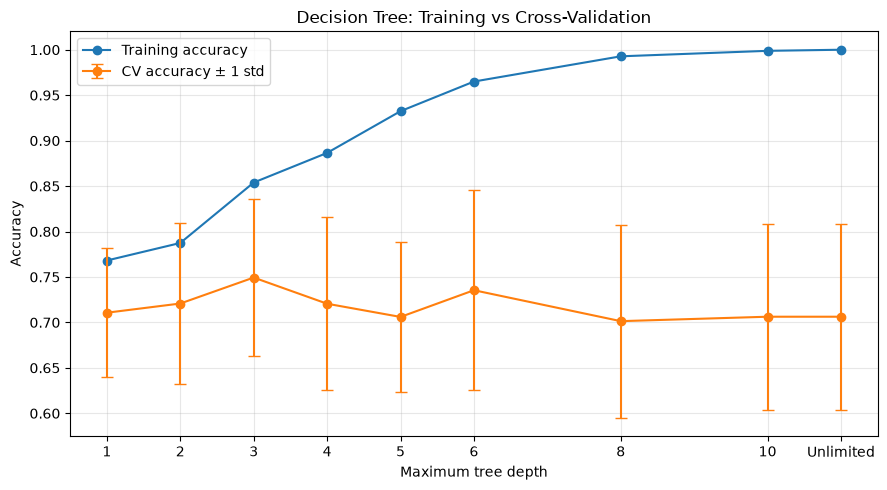

In [13]:
import matplotlib.pyplot as plt

plot_df = depth_df.copy()
plot_df["depth_num"] = [
    11 if d == "None" else int(d)
    for d in plot_df["max_depth"]
]
plot_df = plot_df.sort_values("depth_num")

plt.figure(figsize=(9, 5))
plt.plot(
    plot_df["depth_num"], plot_df["train_accuracy"],
    marker="o", label="Training accuracy"
)
plt.errorbar(
    plot_df["depth_num"], plot_df["cv_accuracy"],
    yerr=plot_df["cv_std"],
    marker="o", capsize=4, label="CV accuracy ± 1 std"
)
plt.xticks(
    plot_df["depth_num"],
    ["1", "2", "3", "4", "5", "6", "8", "10", "Unlimited"]
)
plt.xlabel("Maximum tree depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree: Training vs Cross-Validation")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

c.

Best depth looks to be 3.
Best mean CV accuracy: 0.749
Looks clearly better than it's neigbours and closest to the training accuracy.

d.

In [14]:
leaf_sizes = [1, 2, 5, 10, 20, 40]
leaf_results = []

for leaf_size in leaf_sizes:
    model = DecisionTreeClassifier(
        criterion="entropy",
        max_depth=None,
        min_samples_leaf=leaf_size,
        random_state=SEED
    )
    fitted = model.fit(X_train, y_train)

    leaf_results.append({
        "min_samples_leaf": leaf_size,
        "leaves": fitted.get_n_leaves(),
        "train_accuracy": scores["train_score"].mean(),
        "cv_accuracy": scores["test_score"].mean(),
        "cv_std": scores["test_score"].std()
    })

leaf_df = pd.DataFrame(leaf_results)
display(leaf_df.round(3))

,min_samples_leaf,leaves,train_accuracy,cv_accuracy,cv_std
0,1,36,1.0,0.706,0.102
1,2,34,1.0,0.706,0.102
2,5,20,1.0,0.706,0.102
3,10,11,1.0,0.706,0.102
4,20,7,1.0,0.706,0.102
5,40,5,1.0,0.706,0.102


doesn't seem to give any useful results/

e.

In [15]:
chosen_depth = 3

final_model = DecisionTreeClassifier(criterion="entropy", max_depth=chosen_depth, random_state=SEED)
final_model.fit(X_train, y_train)

test_acc = final_model.score(X_test, y_test)
n_test = len(y_test)

std_error = np.sqrt((test_acc * (1 - test_acc)) / n_test)

print(f"Final Test Accuracy: {test_acc:.4f}")
print(f"Standard Error: {std_error:.4f}")


Final Test Accuracy: 0.8111
Standard Error: 0.0413


## Task 4

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
scores = cross_validate(logreg, X_train, y_train, cv=cv, scoring=("accuracy", "f1"))
print(scores["test_accuracy"].mean(), scores["test_accuracy"].std(), scores["test_f1"].mean())

0.8261324041811846 0.03519681198376135 0.804457088667615


a.

In [17]:
chosen_tree_cv = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=chosen_depth,
    random_state=SEED
)

unlimited_tree_cv = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=None,
    random_state=SEED
)


models = {
    "Chosen tree": chosen_tree_cv,
    "Unlimited tree": unlimited_tree_cv,
    "Logistic regression": logreg
}

comparison_results = []

for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train,
        cv=cv,
        scoring=["accuracy", "f1"]
    )

    comparison_results.append({
        "model": name,
        "cv_accuracy_mean": scores["test_accuracy"].mean(),
        "cv_accuracy_std": scores["test_accuracy"].std(),
        "cv_f1_mean": scores["test_f1"].mean()
    })

comparison_df = pd.DataFrame(comparison_results)
display(comparison_df.round(3))

,model,cv_accuracy_mean,cv_accuracy_std,cv_f1_mean
0,Chosen tree,0.749,0.086,0.689
1,Unlimited tree,0.706,0.102,0.677
2,Logistic regression,0.826,0.035,0.804


Logistic regression	seems to be best

b.

In [18]:
from sklearn.preprocessing import StandardScaler

tree_original = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=chosen_depth,
    random_state=SEED
).fit(X_train, y_train)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

tree_scaled = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=chosen_depth,
    random_state=SEED
).fit(X_train_scaled, y_train)

pred_original = tree_original.predict(X_test)
pred_scaled = tree_scaled.predict(X_test_scaled)

agreement = np.mean(pred_original == pred_scaled)

print(f"Prediction agreement after scaling: {agreement:}")

Prediction agreement after scaling: 1.0


The algorithm shifts the values by a certain cooefficient, the binary partitions will remain unchanged because their order doesnt change but scales by a cooefficient.

c.

In [19]:

from sklearn.metrics import (
    accuracy_score, f1_score, confusion_matrix,
    classification_report
)

final_models = {
    "Chosen tree": DecisionTreeClassifier(
        criterion="entropy",
        max_depth=chosen_depth,
        random_state=SEED
    ),
    "Logistic regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=5000)
    )
}

holdout_results = []

for name, model in final_models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    acc = accuracy_score(y_test, pred)
    f1 = f1_score(y_test, pred, zero_division=0)
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    se = np.sqrt(acc * (1 - acc) / len(y_test))

    holdout_results.append({
        "model": name,
        "accuracy": acc,
        "accuracy_standard_error": se,
        "f1": f1
    })

    print(f"\n{name}")
    print(f"Accuracy: {acc:.3f}")
    print(f"Accuracy standard error: {se:.3f}")
    print(f"F1 score: {f1:.3f}")
    print("Confusion matrix (rows = actual, columns = predicted):")
    print(cm)

display(pd.DataFrame(holdout_results).round(3))


Chosen tree
Accuracy: 0.811
Accuracy standard error: 0.041
F1 score: 0.767
Confusion matrix (rows = actual, columns = predicted):
[[45  3]
 [14 28]]

Logistic regression
Accuracy: 0.844
Accuracy standard error: 0.038
F1 score: 0.825
Confusion matrix (rows = actual, columns = predicted):
[[43  5]
 [ 9 33]]


,model,accuracy,accuracy_standard_error,f1
0,Chosen tree,0.811,0.041,0.767
1,Logistic regression,0.844,0.038,0.825


d.

Logistical reggression is better both accuract and F1 score wise (0.844 and 0.825 compared to Chosen tree 0.811 and 0.767).

Because this difference is smaller than the standard errors of both models (0.041 for the tree and 0.038 for logistic regression), the accuracy gap cannot be confidently told apart from random noise.

Logistic Regression is chosen because it offers balanced, smooth regularized boundaries that yield higher baseline test metrics and a lower accuracy standard error, making it a safer and slightly more stable deployment choice despite the statistical noise overlap.

Task 5

In [20]:
from sklearn.tree import export_text

shallow = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=SEED).fit(X_train, y_train)
print(export_text(shallow, feature_names=feature_names))
ranked = sorted(zip(shallow.feature_importances_, feature_names), reverse=True)
print([(name, round(float(imp), 3)) for imp, name in ranked[:5]])

|--- ca <= 0.50
|   |--- thal <= 6.50
|   |   |--- thalach <= 161.50
|   |   |   |--- class: 0
|   |   |--- thalach >  161.50
|   |   |   |--- class: 0
|   |--- thal >  6.50
|   |   |--- thalach <= 132.00
|   |   |   |--- class: 1
|   |   |--- thalach >  132.00
|   |   |   |--- class: 0
|--- ca >  0.50
|   |--- cp <= 3.50
|   |   |--- oldpeak <= 1.95
|   |   |   |--- class: 0
|   |   |--- oldpeak >  1.95
|   |   |   |--- class: 1
|   |--- cp >  3.50
|   |   |--- oldpeak <= 0.45
|   |   |   |--- class: 1
|   |   |--- oldpeak >  0.45
|   |   |   |--- class: 1

[('ca', 0.394), ('cp', 0.168), ('thal', 0.168), ('thalach', 0.168), ('oldpeak', 0.103)]


In [21]:
tree_ = shallow.tree_
rules = []

def collect_rules(node, conditions):
    left_child = tree_.children_left[node]
    right_child = tree_.children_right[node]

    if left_child == right_child:  # leaf
        predicted_class = int(
            shallow.classes_[np.argmax(tree_.value[node][0])]
        )

        rules.append({
            "conditions": conditions.copy(),
            "prediction": predicted_class,
            "patients": int(tree_.n_node_samples[node])
        })
        return

    feature = feature_names[tree_.feature[node]]
    threshold = tree_.threshold[node]

    collect_rules(
        left_child,
        conditions + [f"{feature} <= {threshold:.3f}"]
    )
    collect_rules(
        right_child,
        conditions + [f"{feature} > {threshold:.3f}"]
    )

collect_rules(0, [])

for target in [1, 0]:
    matching = [r for r in rules if r["prediction"] == target]

    if matching:
        rule = matching[0]
        condition_text = " AND ".join(rule["conditions"])

        print(f"\nRule predicting disease = {target}:")
        print(condition_text if condition_text else "No conditions")
        print(f"Predicted class: {target}")
        print(f"Training patients reaching leaf: {rule['patients']}")
    else:
        print(f"\nNo leaf predicting disease = {target} was found.")


Rule predicting disease = 1:
ca <= 0.500 AND thal > 6.500 AND thalach <= 132.000
Predicted class: 1
Training patients reaching leaf: 8

Rule predicting disease = 0:
ca <= 0.500 AND thal <= 6.500 AND thalach <= 161.500
Predicted class: 0
Training patients reaching leaf: 46


2.

`('ca', 0.394), ('cp', 0.168), ('thal', 0.168), ('thalach', 0.168), ('oldpeak', 0.103)`

These are the 5 most important features displayed.

It is highly biased toward continuous variables or categorical variables with high cardinality

3.

Scikit-learn makes these splits because it focuses on optimizing node purity not accuracy. Even if both sides still have the same majority class, the split separates the data into cleaner pockets. This lowers the total entropy.

In [22]:
import sys
print("Python:", sys.version.split()[0])
print("NumPy:", numpy.__version__)
print("pandas:", pandas.__version__)
print("scikit-learn:", sklearn.__version__)
#The versions provided by the task don't download properly

Python: 3.14.7
NumPy: 2.5.3
pandas: 3.0.6
scikit-learn: 1.9.1


seed: 2666